In [2]:
import sympy as sp

In [38]:
# 1. Definir variable simbólica discreta (entera)


t = sp.symbols("t")
n = sp.symbols('n', integer=True)

## Señales senoidal

$$ x(t) = A*sin(wt+ \phi)$$

### Usando sympy

In [6]:
f = 10   #hz
w = 2*sp.pi*f
phi = 0   #rad
A = 2       # v

x = A * sp.sin(w*t + phi)

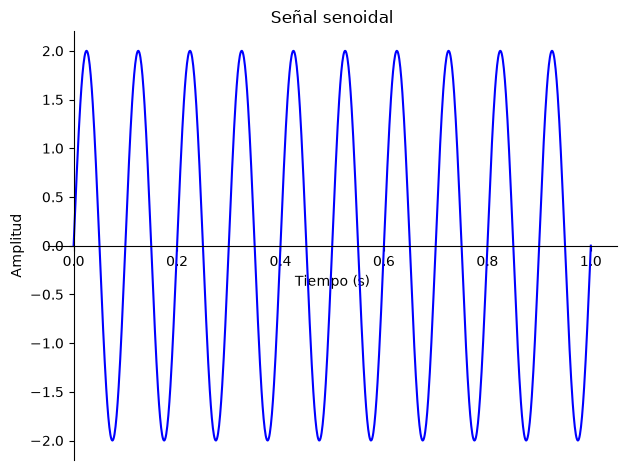

In [7]:
sp.plot(x, (t, 0, 1), title="Señal senoidal", xlabel="Tiempo (s)", ylabel="Amplitud", line_color='blue')

### Pasandolo a numpy

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
x_numpy = sp.lambdify(t, x, modules="numpy")

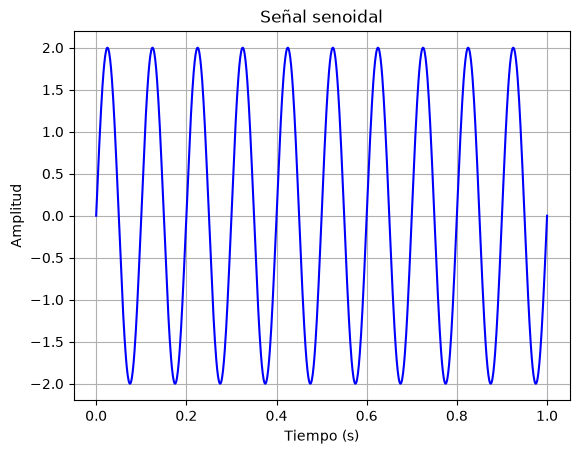

In [11]:
t_values = np.linspace(0, 1, 1000)
x_values = x_numpy(t_values)

plt.plot(t_values, x_values, color='blue')
plt.title("Señal senoidal")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()

## Señal exponencial real negativa

$$ x(t) = e^{-wt} $$

In [25]:
f = 20   #hz
w = 5 #2*sp.pi*f # rad/s

x2 = sp.E**(-1*w*t)

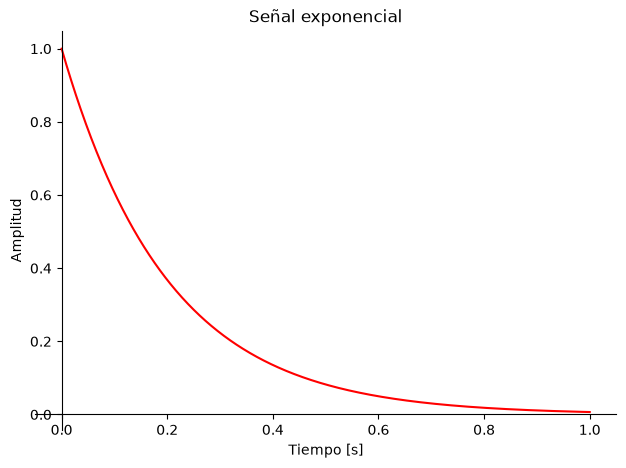

In [26]:
sp.plot(x2, (t, 0, 1), title="Señal exponencial", xlabel="Tiempo [s]", ylabel="Amplitud", line_color='red')

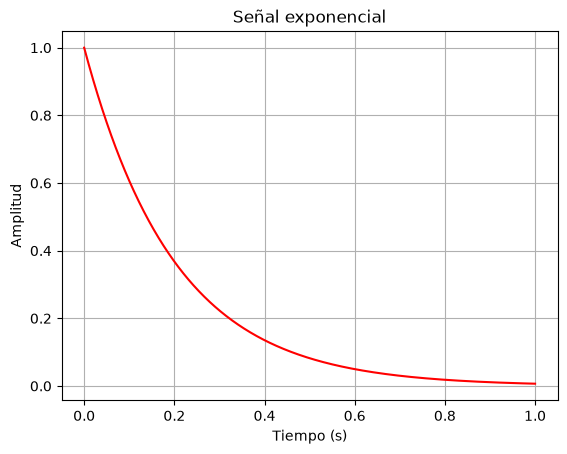

In [27]:
x2_numpy = sp.lambdify(t, x2, modules="numpy")


t_values = np.linspace(0,1, 1000)
x2_values = x2_numpy(t_values)

plt.plot(t_values, x2_values, color='red')
plt.title("Señal exponencial")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.grid()


## Señal amortiguada

$$ x = e^{-\alpha*t}*\sin(w*t+\phi)$$

In [28]:
f = 40
w = 2*sp.pi*f # rad/s
alpha = 5
A= 1
phi = 0

x3 = sp.E**(-1*alpha*t) * A*sp.sin(w*t + phi)

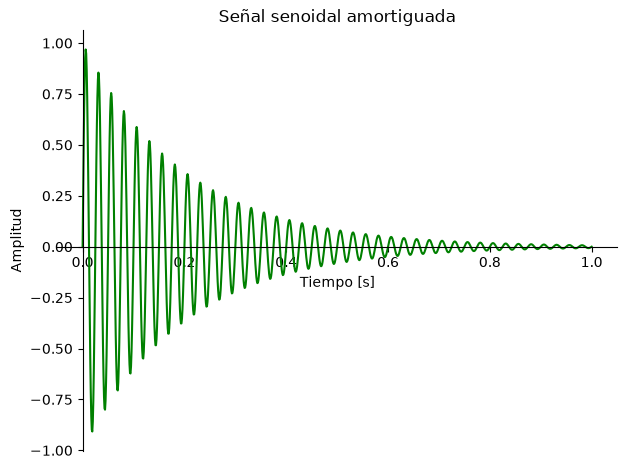

In [29]:
sp.plot(x3, (t,0,1), title="Señal senoidal amortiguada", xlabel="Tiempo [s]", ylabel="Amplitud", line_color='green')

## Delta de Kronecker

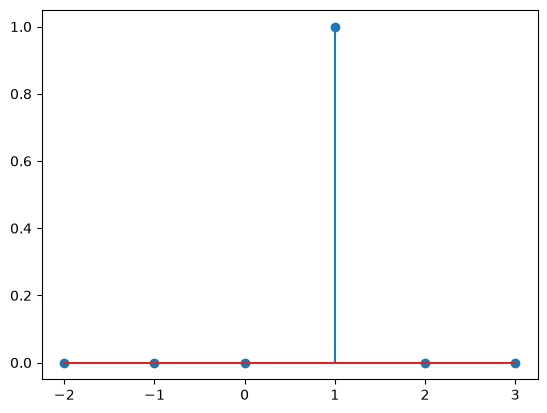

In [43]:


# 2. Definir la Delta de Kronecker en SymPy: delta[n]
# También puedes crear secuencias compuestas, ej: 2*delta[n] - delta[n-3]
x_sym = sp.KroneckerDelta(n, 1)


# Evaluar y graficar
n_val = np.arange(-2, 4)
y_val = [int(x_sym.subs(n, val)) for val in n_val]

plt.stem(n_val, y_val)
plt.xticks(n_val)
plt.show()

In [48]:
# Definir una función que envuelva el .subs()
x_fn = lambda val: int(x_sym.subs(n, val))

# Ahora sí puedes llamarla con paréntesis:
x_fn(1), x_fn(2)   # Devuelve 0

(1, 0)

## Senoidal discreto

$$x[n] = \sum_{k=0}^{N-1} \sin\left(\frac{2\pi}{N} k\right) \delta[n - k]$$

Para digitalizar esta ecuación, se toman muestras cada cierto intervalo fijo llamado período de muestreo (\(T_{s}\)), haciendo el cambio de variable $t = n T_s$:

$$x[n]=\sin(\omega nT_{s})=\sin \left(\frac{2\pi T_{s}}{T}n\right)$$
Si definimos $N = \frac{T}{T_s}$ como la cantidad de muestras que caben en un ciclo completo, la ecuación digital queda:

$$x[n]=\sin \left(\frac{2\pi }{N}n\right)$$

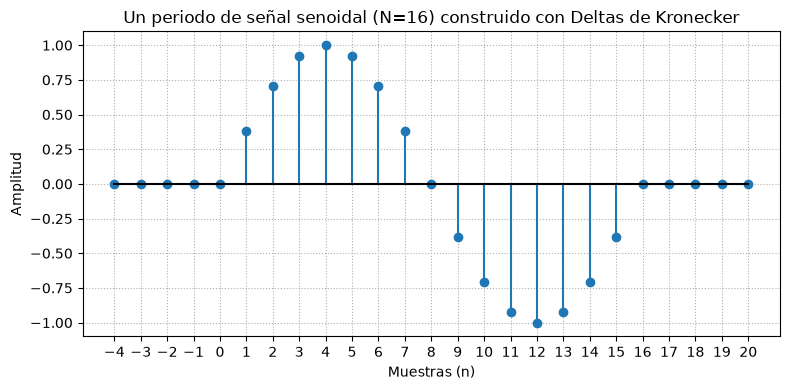

In [49]:
N = 16  

# 2. Construir 1 periodo sumando Deltas de Kronecker desplazadas
# x_sym = sin(0)*delta[n] + sin(2*pi/N)*delta[n-1] + ... + sin(2*pi*(N-1)/N)*delta[n-(N-1)]
x_sym = sum(sp.sin(2 * sp.pi * k / N) * sp.KroneckerDelta(n, k) for k in range(N))

# 3. Evaluar en un rango más amplio (-4 a 20) para ver que fuera del periodo vale 0
n_val = np.arange(-4, 21)
y_val = [float(x_sym.subs(n, val)) for val in n_val]

# 4. Graficar la secuencia discreta
plt.figure(figsize=(8, 4))
plt.stem(n_val, y_val, basefmt="k-")
plt.title(f'Un periodo de señal senoidal (N={N}) construido con Deltas de Kronecker')
plt.xlabel('Muestras (n)')
plt.ylabel('Amplitud')
plt.xticks(n_val)
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.show()